# Dimensionality Reduction - Example Code (PCA, t-SNE, UMAP)

This notebook contains **short examples** of three techniques:
- **PCA** (linear projection, preserves variance)
- **t-SNE** (preserves local neighborhoods, useful for cluster visualization)
- **UMAP** (fast, preserves local and partly global structure)


In [ ]:
# (Only needed once if UMAP is missing)
# Remove the hash (#) below and run this cell:
# !pip install umap-learn


## 1) Importing, loading, and scaling data
We use the **iris** dataset (compact, with 4 numerical features).  
Scaling (mean 0, std 1) is important for PCA/t-SNE/UMAP.


In [1]:
# --- Importing, loading, and scaling data ---
from sklearn.datasets import load_iris            # example dataset
from sklearn.preprocessing import StandardScaler  # bring features to a comparable scale
import matplotlib.pyplot as plt                   # visualization
import numpy as np                                # numerical helper functions

# 1) Load data (iris)
data = load_iris()
X = data.data      # numerical features (shape: [n_samples, n_features])
y = data.target    # labels/classes (0,1,2) - useful for coloring points

# 2) Scale the features (important for many algorithms)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("X_scaled shape:", X_scaled.shape, "| unique labels:", np.unique(y))


X_scaled shape: (150, 4) | unique labels: [0 1 2]


## 2) PCA (Principal Component Analysis)
**What does PCA do?**  
It finds directions with **maximum variance** in the data and projects it into 2D with **minimal information loss** (linearly).


Explained variance ratio (per component): [0.72962445 0.22850762]
Total explained variance: 0.9581320720000164


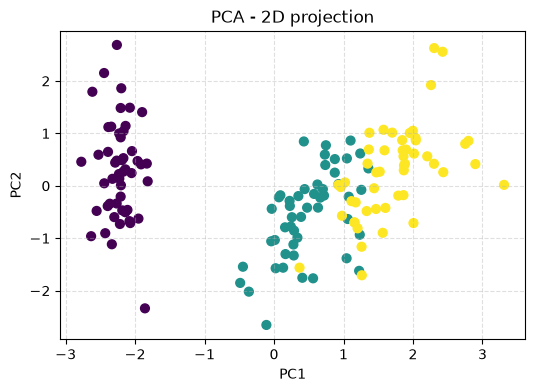

In [2]:
# --- PCA: linear reduction to 2D, preserving as much variance as possible ---
from sklearn.decomposition import PCA

# 1) PCA with 2 components
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

# 2) Explanation/diagnostics: how much variance does each component capture?
print("Explained variance ratio (per component):", pca.explained_variance_ratio_)
print("Total explained variance:", pca.explained_variance_ratio_.sum())

# 3) Visualization (each point is an iris sample, colored by class)
plt.figure(figsize=(6,4))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y, s=40)  # no explicit colormap -> default
plt.title("PCA - 2D projection")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.grid(True, linestyle="--", alpha=0.4)
plt.show()


## 3) t-SNE (t-Distributed Stochastic Neighbor Embedding)
**What does t-SNE do?**  
It focuses on preserving **local neighborhoods** (points that belong close together).  
Useful for making **clusters** visible. Global distances are less reliable.


In [ ]:
# --- t-SNE: focuses on local structure / cluster formation ---
from sklearn.manifold import TSNE

# 1) Run t-SNE (without PCA initialization, as requested)
# - perplexity ~= average number of 'neighbors'; 30 is often a reasonable starting value
# - random_state for reproducibility
tsne = TSNE(n_components=2, perplexity=30, random_state=42)
X_tsne = tsne.fit_transform(X_scaled)

# 2) Visualization
plt.figure(figsize=(6,4))
plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=y, s=40)  # no explicit colormap -> default
plt.title("t-SNE - 2D projection (perplexity=30)")
plt.xlabel("Dim 1")
plt.ylabel("Dim 2")
plt.grid(True, linestyle="--", alpha=0.4)
plt.show()


## 4) UMAP (Uniform Manifold Approximation and Projection)
**What does UMAP do?**  
It tries to preserve both **local** and (partly) **global** structure and is usually **faster** than t-SNE.
Important settings:
- `n_neighbors` (a small value focuses more on local details)
- `min_dist` (how close points in a cluster may be to one another)


In [ ]:
# --- Installing UMAP ---
# UMAP is not included by default in scikit-learn.
# If you get the following error:
#   ModuleNotFoundError: No module named 'umap'
# you must first install the package with pip.
#
# Remove the '#' character below and run this cell (only needed once per environment):

#!pip install umap-learn
#
# After installation, you can run the next cell (the UMAP code).


In [ ]:
# --- UMAP: fast and preserves local + partly global structure ---
import umap

# 1) Run UMAP with common starting values
umap_model = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=42)
X_umap = umap_model.fit_transform(X_scaled)

# 2) Visualization
plt.figure(figsize=(6,4))
plt.scatter(X_umap[:, 0], X_umap[:, 1], c=y, s=40)  # no explicit colormap -> default
plt.title("UMAP - 2D projection (n_neighbors=15, min_dist=0.1)")
plt.xlabel("Dim 1")
plt.ylabel("Dim 2")
plt.grid(True, linestyle="--", alpha=0.4)
plt.show()




**Tip:** For the demo, vary `perplexity` (t-SNE), `n_neighbors`, and `min_dist` (UMAP) to see the effects live.
